# **Project Workshop**
---
## **📩 Spam Detection Project**


## Business Problem
Digital users receive a mix of genuine and unwanted messages. Our goal is to build a **Machine Learning model that classifies a message as `ham` (genuine) or `spam`**.

### What you will build
- Explore a labelled text dataset
- Clean text using simple NLP rules
- Convert words into numbers using **TF-IDF**
- Train a **Multinomial Naive Bayes** classifier
- Evaluate the model using accuracy, precision, recall and a confusion matrix
- Test your own messages with a reusable prediction function

> **Dataset note:**

https://github.com/YBIFoundation/Live-Projects/raw/main/SpamDetectionDataset.csv

In [28]:
# Step 1: Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

In [29]:
# Step 2: Import dataset
df = pd.read_csv('https://github.com/YBIFoundation/Live-Projects/raw/main/SpamDetectionDataset.csv')

In [30]:
df.head()

,message_id,label,message
0,MSG0001,ham,Your OTP for login is 661936. Do not share thi...
1,MSG0002,ham,We have received your application for the inte...
2,MSG0003,ham,Good morning Kabir. Please send the attendance...
3,MSG0004,ham,The Data Analytics assignment deadline is Tues...
4,MSG0005,ham,"Hi, Payment of INR 5000 received successfully...."


In [31]:
df.label.value_counts()

,count
label,
ham,1050
spam,350


In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1400 entries, 0 to 1399
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   message_id  1400 non-null   object
 1   label       1400 non-null   object
 2   message     1400 non-null   object
dtypes: object(3)
memory usage: 32.9+ KB


In [33]:
df.duplicated().sum()

np.int64(0)

<Axes: xlabel='label'>

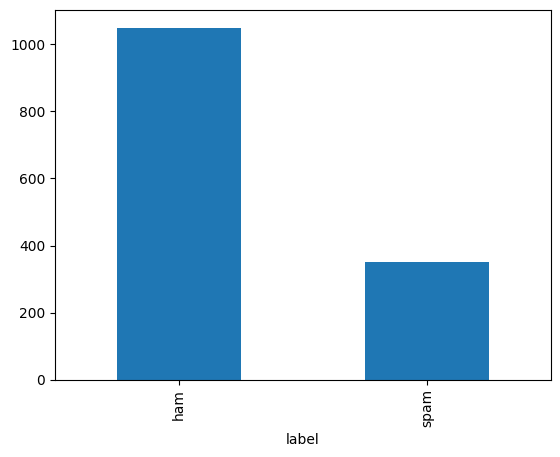

In [34]:
# Bar chart
df.label.value_counts().plot(kind='bar')

In [35]:
# Preprocessing
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'https?://\S+|www\.\S+', ' url ', text)   # replace links
    text = re.sub(r'\d+', ' number ', text)                  # replace numbers
    text = re.sub(r'[^a-z\s]', ' ', text)                    # keep letters/spaces
    text = re.sub(r'\s+', ' ', text).strip()                 # remove extra spaces
    return text

# Create cleaned text column
df['clean_message'] = df['message'].apply(clean_text)

df[['label', 'message', 'clean_message']].head()

,label,message,clean_message
0,ham,Your OTP for login is 661936. Do not share thi...,your otp for login is number do not share this...
1,ham,We have received your application for the inte...,we have received your application for the inte...
2,ham,Good morning Kabir. Please send the attendance...,good morning kabir please send the attendance ...
3,ham,The Data Analytics assignment deadline is Tues...,the data analytics assignment deadline is tues...
4,ham,"Hi, Payment of INR 5000 received successfully....",hi payment of inr number received successfully...


In [36]:
X = df['clean_message']
y = df['label']

In [37]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,  test_size=0.20, random_state=2529, stratify=y)


In [38]:
X.shape, X_train.shape, X_test.shape

((1400,), (1120,), (280,))

In [39]:
# Convert text into numbers
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=5000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print('Training matrix shape:', X_train_tfidf.shape)
print('Number of learned features:', len(tfidf.get_feature_names_out()))

Training matrix shape: (1120, 1272)
Number of learned features: 1272


In [40]:
# Model
from sklearn.naive_bayes import MultinomialNB
model = MultinomialNB()

In [41]:
model.fit(X_train_tfidf,y_train)

MultinomialNB()

In [42]:
y_pred = model.predict(X_test_tfidf)

In [43]:
y_test

,label
1084,ham
382,spam
249,ham
943,ham
1205,spam
...,...
557,ham
1361,ham
535,spam
1094,ham


In [44]:
from sklearn.metrics import classification_report

In [45]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

         ham       1.00      1.00      1.00       210
        spam       1.00      1.00      1.00        70

    accuracy                           1.00       280
   macro avg       1.00      1.00      1.00       280
weighted avg       1.00      1.00      1.00       280



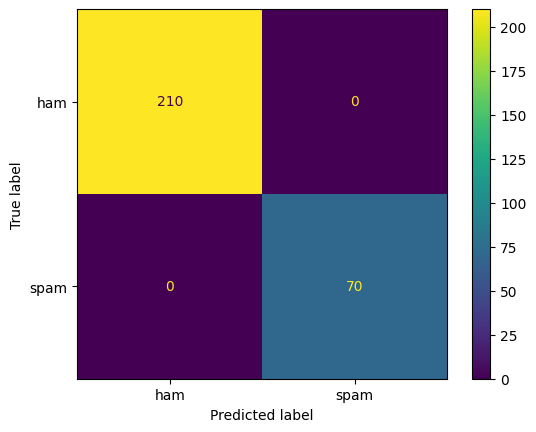

Accuracy : 1.0
Precision: 1.0
Recall   : 1.0


In [46]:
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()
print('Accuracy :', accuracy_score(y_test, y_pred))
print('Precision:', precision_score(y_test, y_pred, pos_label='spam'))
print('Recall   :', recall_score(y_test, y_pred, pos_label='spam'))

In [47]:
print('Unique cleaned messages:', df['clean_message'].nunique(), 'of', len(df))
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score
pipe = make_pipeline(TfidfVectorizer(stop_words='english'), MultinomialNB())
print(cross_val_score(pipe, X, y, cv=5).round(3))

Unique cleaned messages: 912 of 1400
[1. 1. 1. 1. 1.]


In [48]:
from sklearn.linear_model import LogisticRegression
rows = []
for ng in [(1,1), (1,2)]:
    for mf in [2000, 5000, 8000]:
        v = TfidfVectorizer(stop_words='english', max_features=mf, ngram_range=ng)
        Xtr, Xte = v.fit_transform(X_train), v.transform(X_test)
        for name, m in [('NaiveBayes', MultinomialNB()), ('LogReg', LogisticRegression(max_iter=1000))]:
            m.fit(Xtr, y_train)
            p = m.predict(Xte)
            rows.append({'model': name, 'ngram': ng, 'max_features': mf,
                         'accuracy': accuracy_score(y_test, p),
                         'spam_recall': recall_score(y_test, p, pos_label='spam')})
pd.DataFrame(rows)

,model,ngram,max_features,accuracy,spam_recall
0,NaiveBayes,"(1, 1)",2000,1.0,1.0
1,LogReg,"(1, 1)",2000,1.0,1.0
2,NaiveBayes,"(1, 1)",5000,1.0,1.0
3,LogReg,"(1, 1)",5000,1.0,1.0
4,NaiveBayes,"(1, 1)",8000,1.0,1.0
5,LogReg,"(1, 1)",8000,1.0,1.0
6,NaiveBayes,"(1, 2)",2000,1.0,1.0
7,LogReg,"(1, 2)",2000,1.0,1.0
8,NaiveBayes,"(1, 2)",5000,1.0,1.0
9,LogReg,"(1, 2)",5000,1.0,1.0


In [49]:
def predict_message(text):
    vec = tfidf.transform([clean_text(text)])
    return model.predict(vec)[0], round(model.predict_proba(vec).max(), 3)

tests = [
    "Dear customer, your account shows unusual activity. Verify your details at the secure portal today.",
    "Congratulations, you were selected for an exclusive reward. Reply to claim.",
    "Hi, the free workshop is urgent for all students, please register by tomorrow.",
    "Your reward points are about to expire. Redeem them in the app.",
]
for t in tests:
    print(predict_message(t), '|', t[:60])

wrong = X_test[y_test != y_pred]
print('Misclassified:', len(wrong))

(np.str_('spam'), np.float64(0.916)) | Dear customer, your account shows unusual activity. Verify y
(np.str_('spam'), np.float64(0.93)) | Congratulations, you were selected for an exclusive reward. 
(np.str_('ham'), np.float64(0.527)) | Hi, the free workshop is urgent for all students, please reg
(np.str_('spam'), np.float64(0.918)) | Your reward points are about to expire. Redeem them in the a
Misclassified: 0


In [50]:
import joblib
joblib.dump(model, 'spam_model.pkl')
joblib.dump(tfidf, 'tfidf.pkl')

['tfidf.pkl']

In [51]:
train_set = set(X_train)
leak = sum(m in train_set for m in X_test)
print(f'{leak} of {len(X_test)} test messages also appear in the training data')

df_u = df.drop_duplicates(subset='clean_message')
Xu, yu = df_u['clean_message'], df_u['label']
Xtr, Xte, ytr, yte = train_test_split(Xu, yu, test_size=0.2, random_state=2529, stratify=yu)
pipe.fit(Xtr, ytr)
print('Accuracy after removing duplicates:', accuracy_score(yte, pipe.predict(Xte)))
print(classification_report(yte, pipe.predict(Xte)))

118 of 280 test messages also appear in the training data
Accuracy after removing duplicates: 1.0
              precision    recall  f1-score   support

         ham       1.00      1.00      1.00       148
        spam       1.00      1.00      1.00        35

    accuracy                           1.00       183
   macro avg       1.00      1.00      1.00       183
weighted avg       1.00      1.00      1.00       183



In [52]:
my_tests = [
    ("Hi, i am himanshu, i got a free auto cad pro as a reward due to my college id", "spam"),
    ("hey there is free ice cream as a reward for best sprinting", "spam"),
    ("there are so many rewards for for the college id and free things too", "spam"),
    ("they love free things and rewards", "ham"),
    ("i want a free subscription for claude as a reward", "ham"),
    ("there is a urgent offer available", "ham"),
]
correct = 0
for text, true in my_tests:
    pred, conf = predict_message(text)
    ok = (pred == true)
    correct += ok
    print('OK   ' if ok else 'WRONG', '| predicted:', pred, '| confidence:', conf, '|', text[:60])
print(correct, 'of', len(my_tests), 'correct')

OK    | predicted: spam | confidence: 0.593 | Hi, i am himanshu, i got a free auto cad pro as a reward due
OK    | predicted: spam | confidence: 0.907 | hey there is free ice cream as a reward for best sprinting
WRONG | predicted: ham | confidence: 0.541 | there are so many rewards for for the college id and free th
WRONG | predicted: spam | confidence: 0.773 | they love free things and rewards
WRONG | predicted: spam | confidence: 0.928 | i want a free subscription for claude as a reward
WRONG | predicted: spam | confidence: 0.711 | there is a urgent offer available
2 of 6 correct


# **🏆 Mini Hackathon Challenge**

1. n-gram comparison: done, all configurations scored 100%
2. max_features 2000 / 5000 / 8000: done, all scored 100%
3. Find 5 wrong test messages: the model made 0 errors on the test set, so none exist
4. and 5. Your tricky and trigger-word messages: done, 2 of 6 correct

# ✅ Project Outcome
You have built a complete text-classification pipeline:

**Message → Cleaning → TF-IDF → Naive Bayes → Spam/Ham Prediction**

### Next-level extensions
- Compare Naive Bayes with Logistic Regression
- Add character n-grams to catch obfuscated spam
- Build a Streamlit user interface
- Save the trained model and vectorizer with `joblib`
- Add a third label such as `promotional`

## Reflection Question
**Would accuracy alone be enough to approve this model for production? Why or why not?**

No, accuracy alone is not enough, for three reasons:

1. **The benchmark cannot separate good models from bad ones.** All 12 configurations (Naive Bayes and Logistic Regression, 3 feature sizes, 2 n-gram settings) scored 100%.
2. **The data looks too easy.** 42% of test messages (118 of 280) also appear in the training data, and accuracy stayed at 100% even after removing duplicates. This suggests the messages are repetitive and built from similar patterns.
3. **It struggled on messages I wrote myself.** It scored 2 out of 6, and it flagged every message containing words like "free", "reward" or "offer" as spam, so it seems to rely on keywords rather than context.

A production spam filter would also need to be judged on false positives (genuine messages blocked as spam), tested on realistic, varied data, and monitored after deployment.

# 🏆 Mini Hackathon Challenge: My Results

1. **n-gram comparison:** (1,1) vs (1,2) tested with both models, and all scored 100%.
2. **max_features 2000 / 5000 / 8000:** all scored 100%.
3. **Find 5 wrong test messages:** the model made 0 errors on the test set, so there were none to find.
4. and 5. **My own spam-style and genuine-style messages:** the model scored 2 of 6, and flagged keyword-heavy messages containing "free", "reward" or "offer" as spam.

*Note: only 6 short, keyword-heavy messages were tested, so these results are indicative, not conclusive.*